# Data cleaning and validation

## MODIS data

#### %load_ext autoreload  is important so that when a function is added to data_pipeline.py there's no need to restart all variables

In [1]:
%load_ext autoreload 
%autoreload 2
from data_pipeline import audit_platform_coverage, read_data_modis, read_data_viirs_c2, read_data_viirs_j1, read_data_viirs_j2, read_all_data_archive, categorical_mapping, combine_firms_datasets, aggregate_detection_grid, add_spatial_grid, assign_estimated_fire_events, compare_temperature_distributions, compare_platforms_daynight, analyze_sensor_platform_correlations, show_memory_usage
from helper import plot_all_correlation_results


In [2]:
dfs = read_all_data_archive()

modis_df = dfs["MODIS"]
j1v_df = dfs["J1V"]
j2v_df = dfs["J2V"]

In [3]:
len(dfs)

3

In [4]:
for df in dfs:
    print(df)
    print(dfs[df].columns.tolist())
    print(dfs[df]["version"].value_counts(dropna=False))


MODIS
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'source_file']
version
61.03    2623542
Name: count, dtype: int64
J1V
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'source_file']
version
2    11269989
Name: count, dtype: int64
J2V
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'source_file']
version
2    10802644
Name: count, dtype: int64


In [5]:
for name, df in dfs.items():

    print(f"\n{'=' * 20} {name} {'=' * 20}")

    print("Instrument:")
    print(df["instrument"].value_counts(dropna=False))

    print("\nSatellite:")
    print(df["satellite"].value_counts(dropna=False))

    print("\nConfidence:")
    print(df["confidence"].value_counts(dropna=False).head(10))

    print("\nTemperature fields:")
    print(
        df[["brightness", "bright_t31"]]
        .describe()
    )

    print("\nMissing values:")
    print(
        df[["brightness", "bright_t31"]]
        .isna()
        .sum()
    )


==================== MODIS ====================
Instrument:
instrument
MODIS    2623542
Name: count, dtype: int64

Satellite:
satellite
Aqua     1865200
Terra     758342
Name: count, dtype: int64

Confidence:
confidence
100    159591
66      58583
65      57974
67      57962
68      57748
69      57278
63      57106
64      57101
70      56596
71      55645
Name: count, dtype: int64

Temperature fields:
         brightness    bright_t31
count  2.623542e+06  2.623542e+06
mean   3.218910e+02  2.979144e+02
std    1.713974e+01  7.946663e+00
min    3.000000e+02  2.643000e+02
25%    3.117000e+02  2.934000e+02
50%    3.182000e+02  2.983000e+02
75%    3.269000e+02  3.025000e+02
max    5.092000e+02  4.001000e+02

Missing values:
brightness    0
bright_t31    0
dtype: int64

==================== J1V ====================
Instrument:
instrument
VIIRS    11269989
Name: count, dtype: int64

Satellite:
satellite
N20    11269989
Name: count, dtype: int64

Confidence:
confidence
n    9479696
l    1298

In [6]:

summary = compare_temperature_distributions({
    "MODIS": modis_df,
    "J1V": j1v_df,
    "J2V": j2v_df
})

print(summary)

                brightness                          bright_t31           \
                     count     mean  median     std      count     mean   
source daynight                                                           
J1V    D           8516545  341.228  339.51  10.262    8516545  302.162   
       N           2753444  311.945  307.88  13.720    2753444  286.710   
J2V    D           8126265  341.219  339.34  10.960    8126265  302.495   
       N           2676379  311.944  307.94  13.675    2676379  286.954   
MODIS  D           2179048  323.192  319.40  16.715    2179048  299.348   
       N            444494  315.514  310.10  17.754     444494  290.884   

                                
                 median    std  
source daynight                 
J1V    D         302.36  8.783  
       N         288.24  8.672  
J2V    D         302.72  8.803  
       N         288.43  8.627  
MODIS  D         299.50  7.412  
       N         291.50  6.627  


In [7]:
summary = compare_platforms_daynight(dfs)

print(summary)

                     count  mid_mean  mid_median  mid_std  thermal_mean  \
platform daynight                                                         
Aqua     D         1773483   324.132      320.30   16.725       300.173   
         N           91717   314.209      309.30   16.233       289.463   
J1V      D         8516545   341.228      339.51   10.262       302.162   
         N         2753444   311.945      307.88   13.720       286.710   
J2V      D         8126265   341.219      339.34   10.960       302.495   
         N         2676379   311.944      307.94   13.675       286.954   
Terra    D          405565   319.081      315.50   16.040       295.744   
         N          352777   315.853      310.20   18.114       291.254   

                   thermal_median  thermal_std  
platform daynight                               
Aqua     D                 300.20        7.236  
         N                 290.20        6.683  
J1V      D                 302.36        8.783  
    

In [8]:

coverage = audit_platform_coverage({
    "MODIS": modis_df,
    "J1V": j1v_df,
    "J2V": j2v_df
})

print(coverage.to_string(index=False))

source satellite daynight  detections first_date  last_date  unique_dates  source_files
 MODIS      Aqua        D     1773483 2025-11-14 2026-08-31           291             1
 MODIS      Aqua        N       91717 2025-11-14 2026-08-31           291             1
 MODIS     Terra        D      405565 2025-11-14 2026-08-31           290             1
 MODIS     Terra        N      352777 2025-11-14 2026-08-31           290             1
   J1V       N20        D     8516545 2025-11-14 2026-07-31           260             1
   J1V       N20        N     2753444 2025-11-14 2026-07-31           260             1
   J2V       N21        D     8126265 2025-11-14 2026-07-31           260             1
   J2V       N21        N     2676379 2025-11-14 2026-07-31           260             1


In [9]:
import pandas as pd


combined_df = combine_firms_datasets(
    dfs,
    extra_spatial_features=False
)

show_memory_usage(combined_df, "Harmonized dataset")

correlation_results = analyze_sensor_platform_correlations(
    combined_df,
    encoder_root="encoder/categorical",
    correlation_root="correlations",
    sample_size=250_000,
    random_state=42,
    include_coordinates=False
)

MODIS: 2,623,542 records harmonized
J1V: 11,269,989 records harmonized
J2V: 10,802,644 records harmonized
Harmonized dataset: 1,837.07 MB (1.79 GB)
float32                10
category                2
float64                 2
category                1
category                1
category                1
category                1
bool                    1
datetime64[us, UTC]     1
category                1
category                1
int8                    1
category                1
category                1
category                1
category                1
Name: count, dtype: int64

Analyzing MODIS / Terra
  ALL: 250,000 sampled from 758,342 records
  DAY: 250,000 sampled from 405,565 records
  NIGHT: 250,000 sampled from 352,777 records

Analyzing MODIS / Aqua
  ALL: 250,000 sampled from 1,865,200 records
  DAY: 250,000 sampled from 1,773,483 records
  NIGHT: 91,717 sampled from 91,717 records

Analyzing VIIRS / NOAA-20
  ALL: 250,000 sampled from 11,269,989 records
  DAY: 250,000 sa

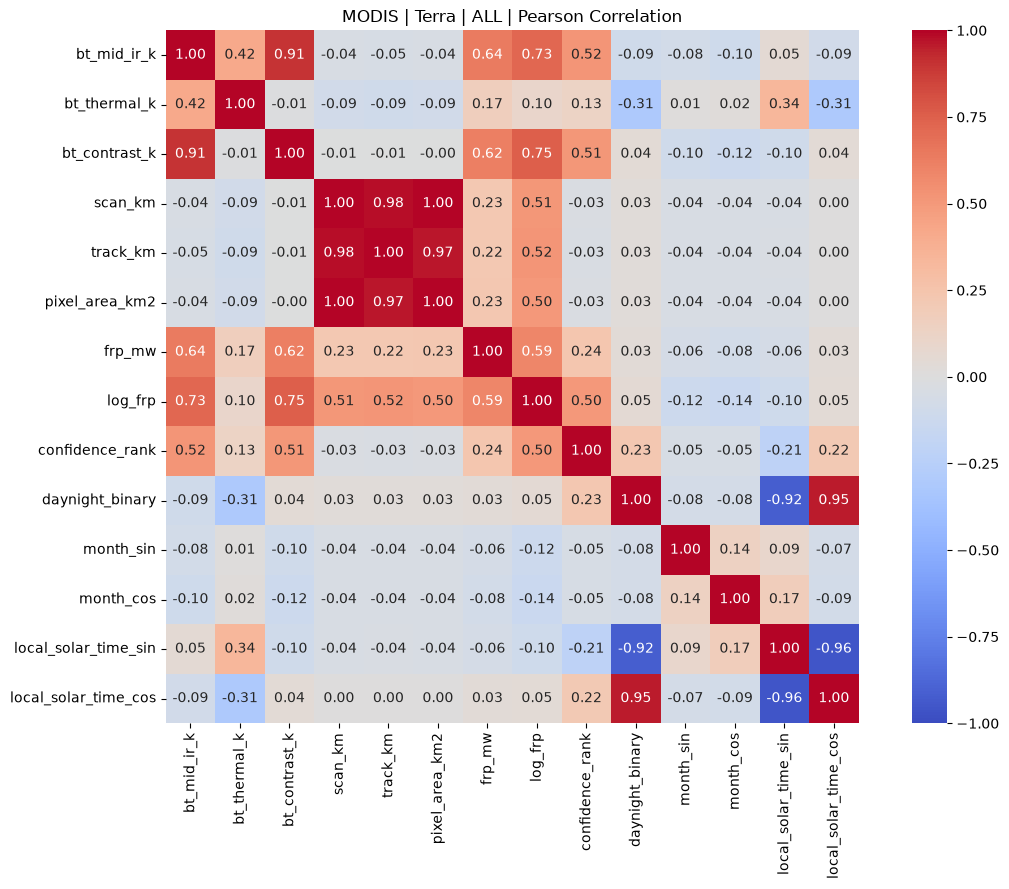

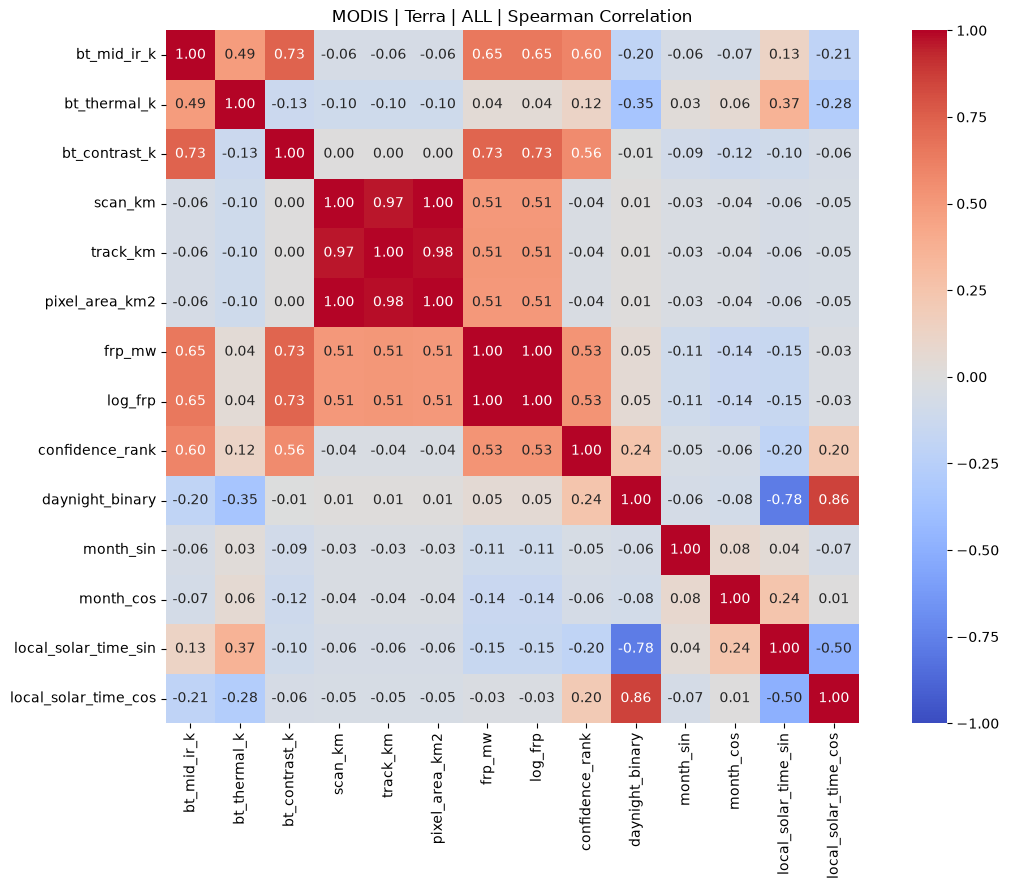

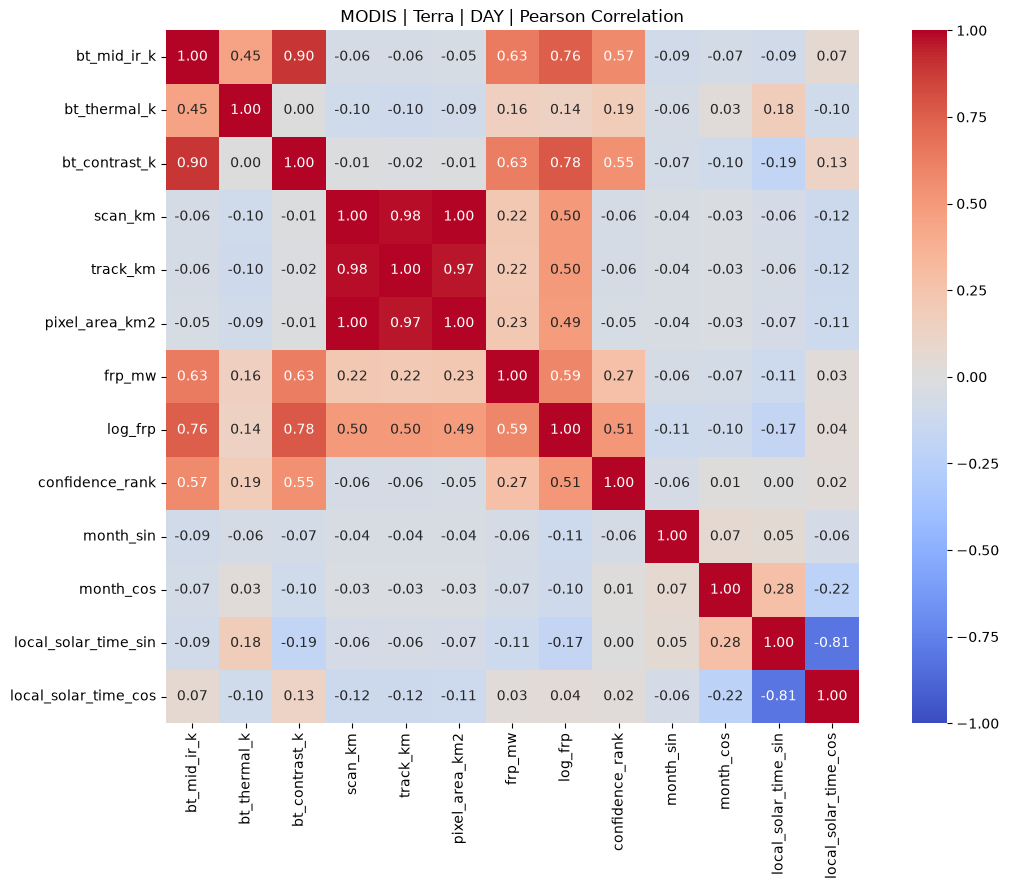

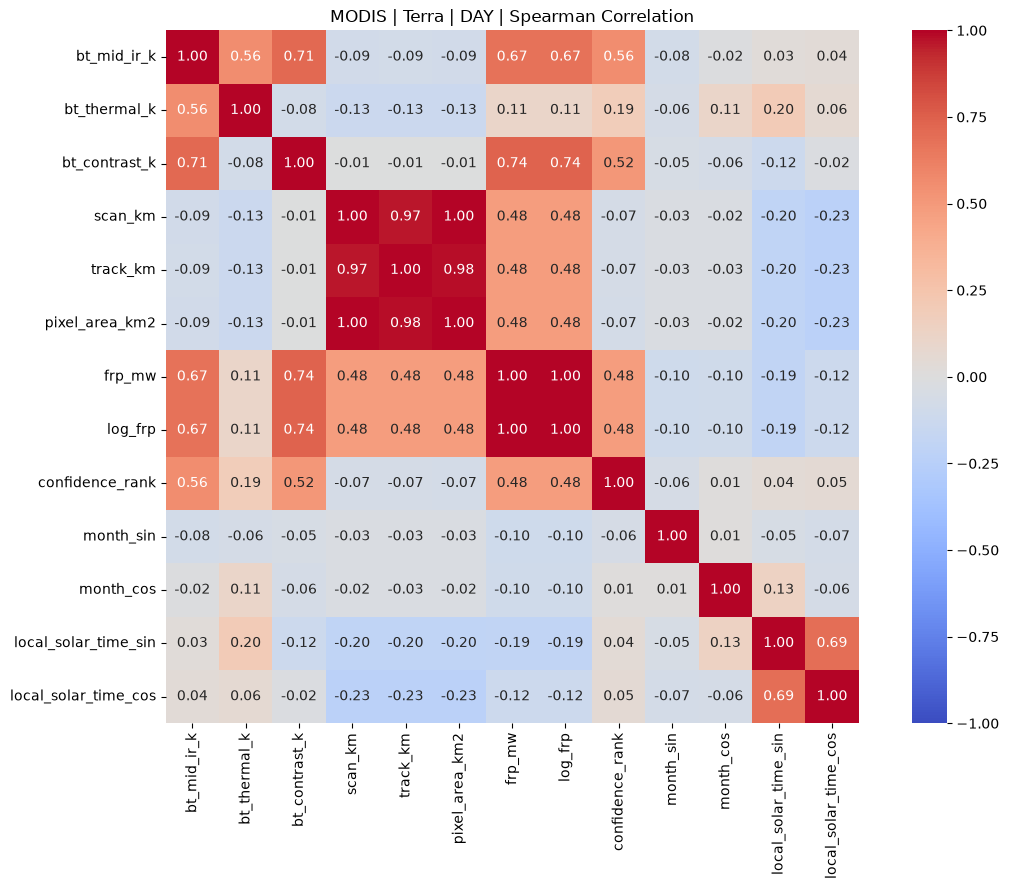

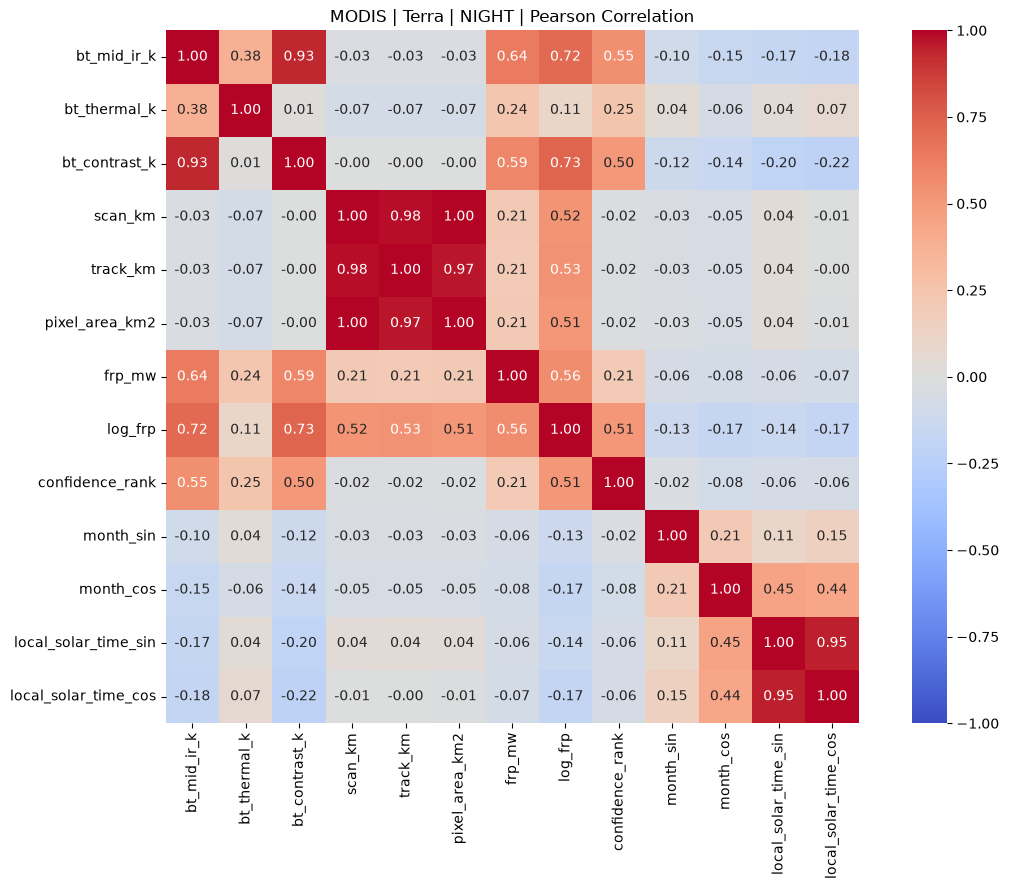

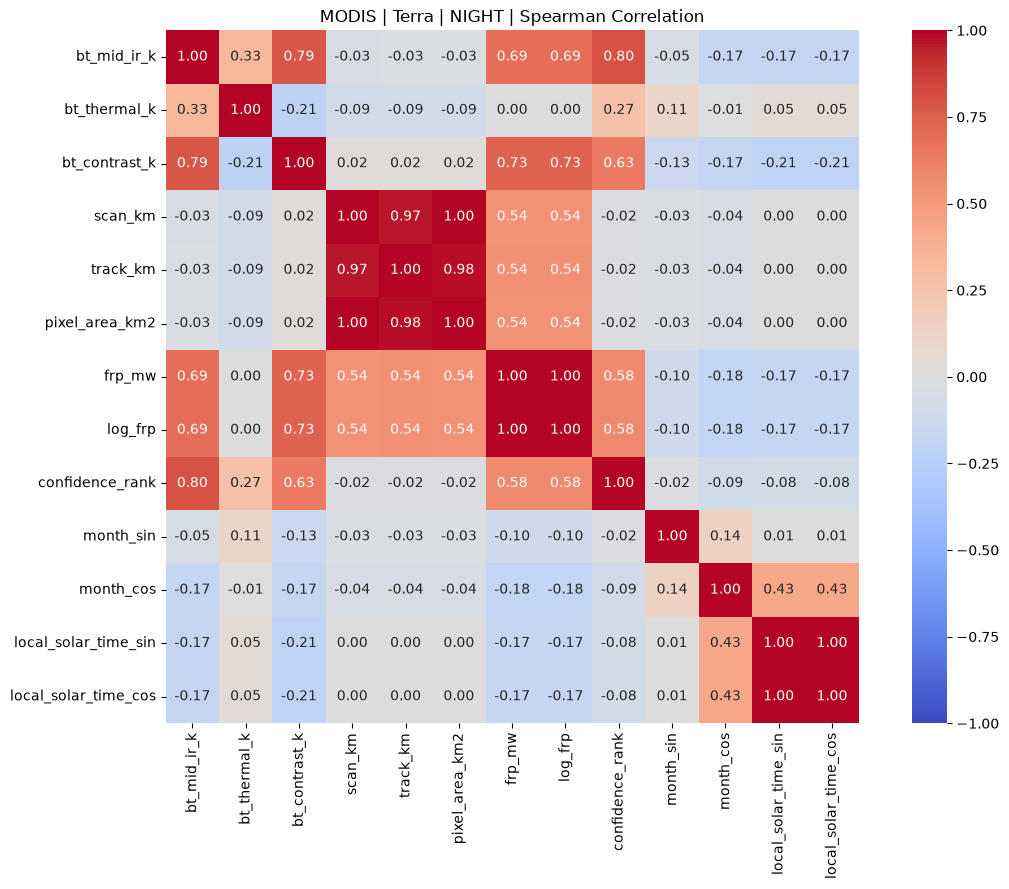

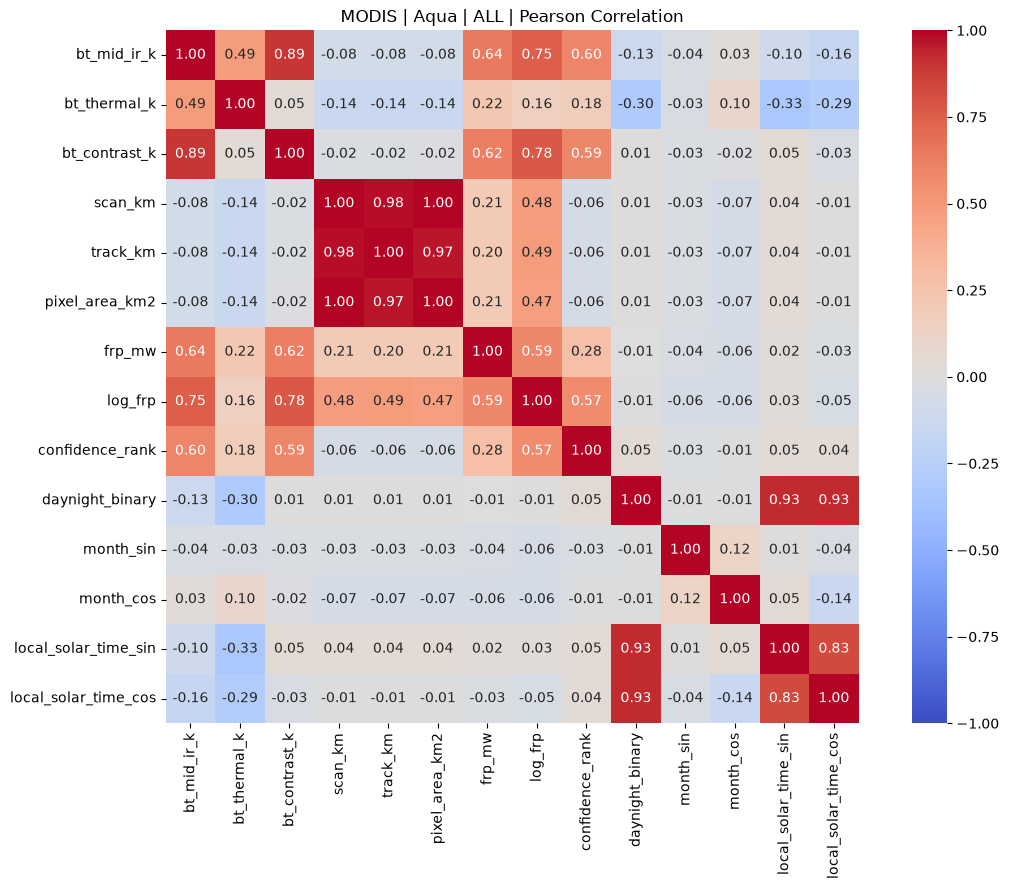

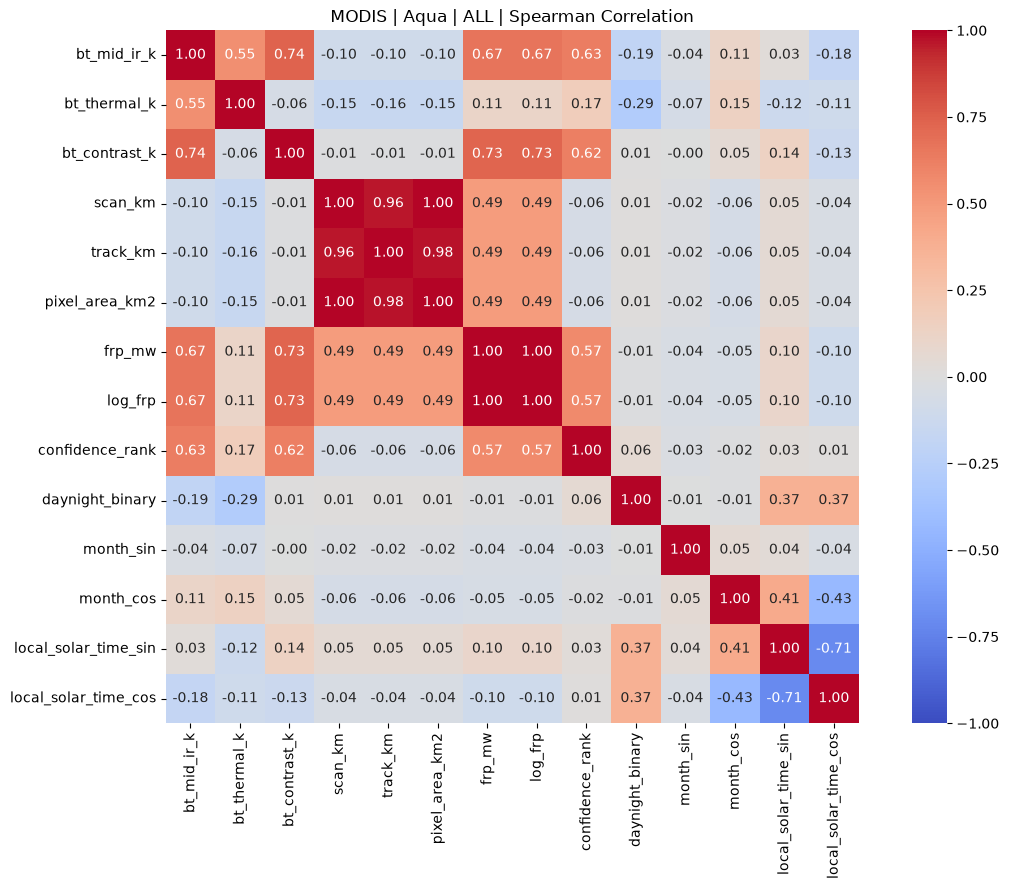

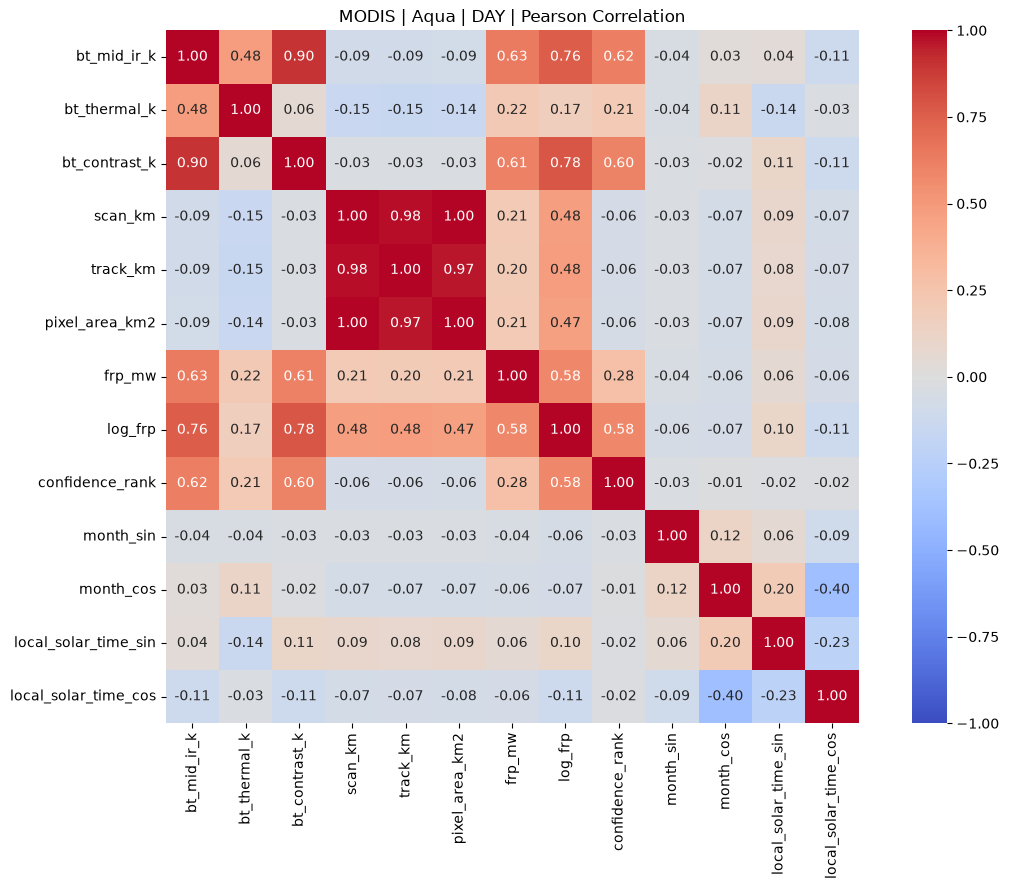

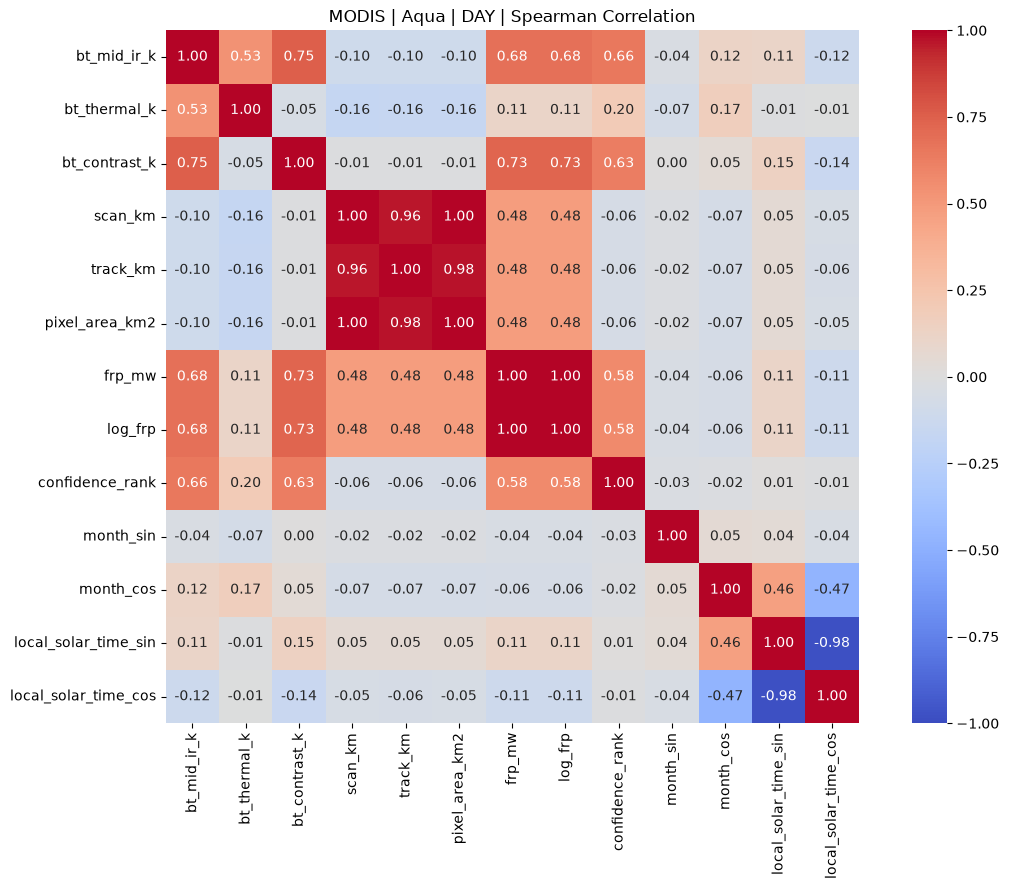

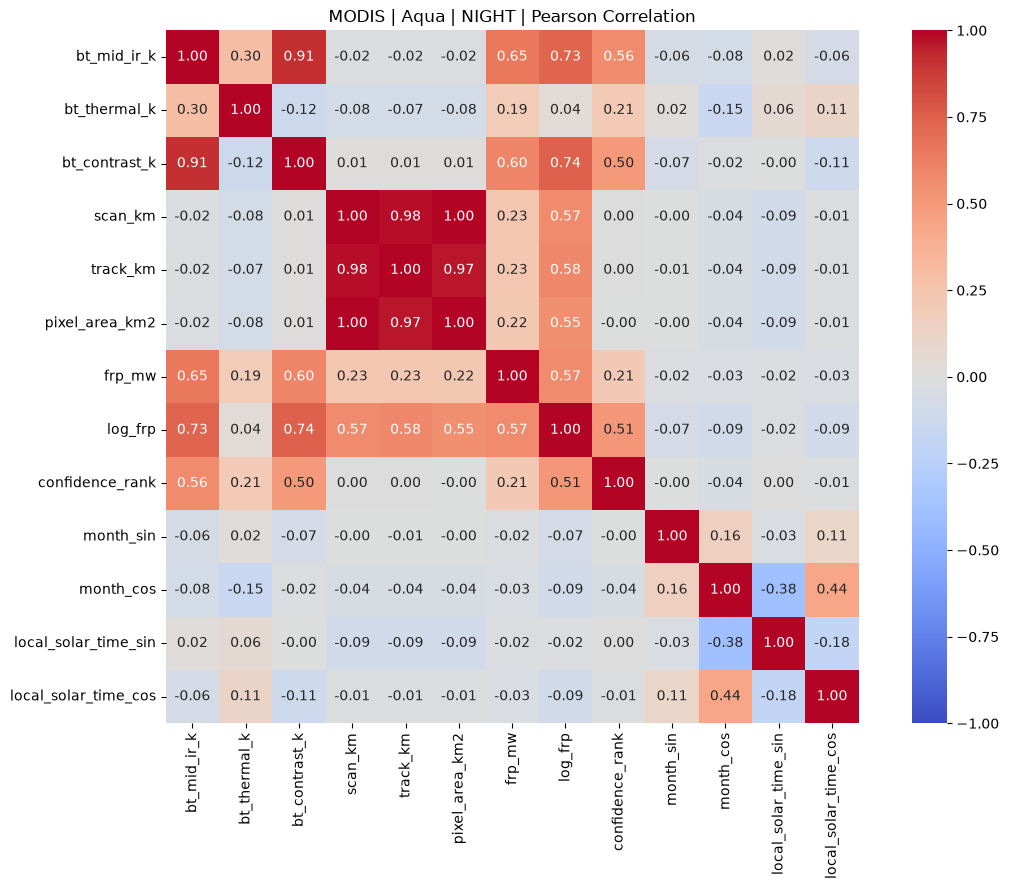

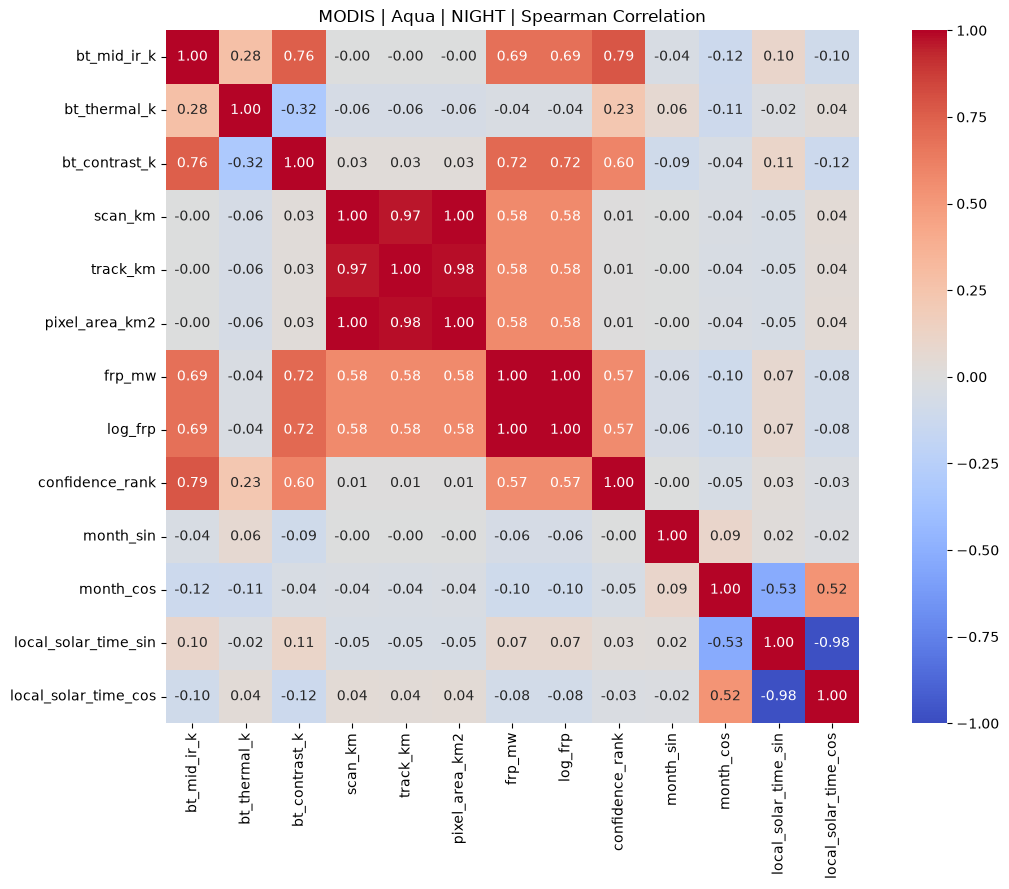

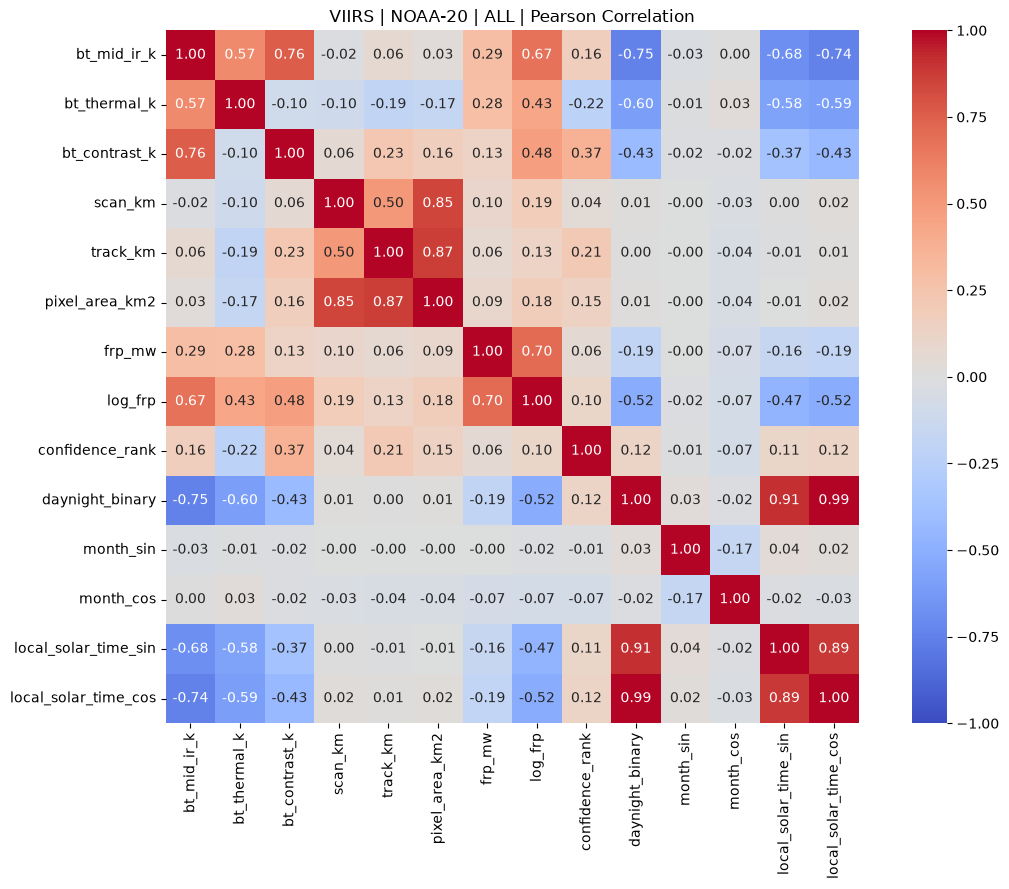

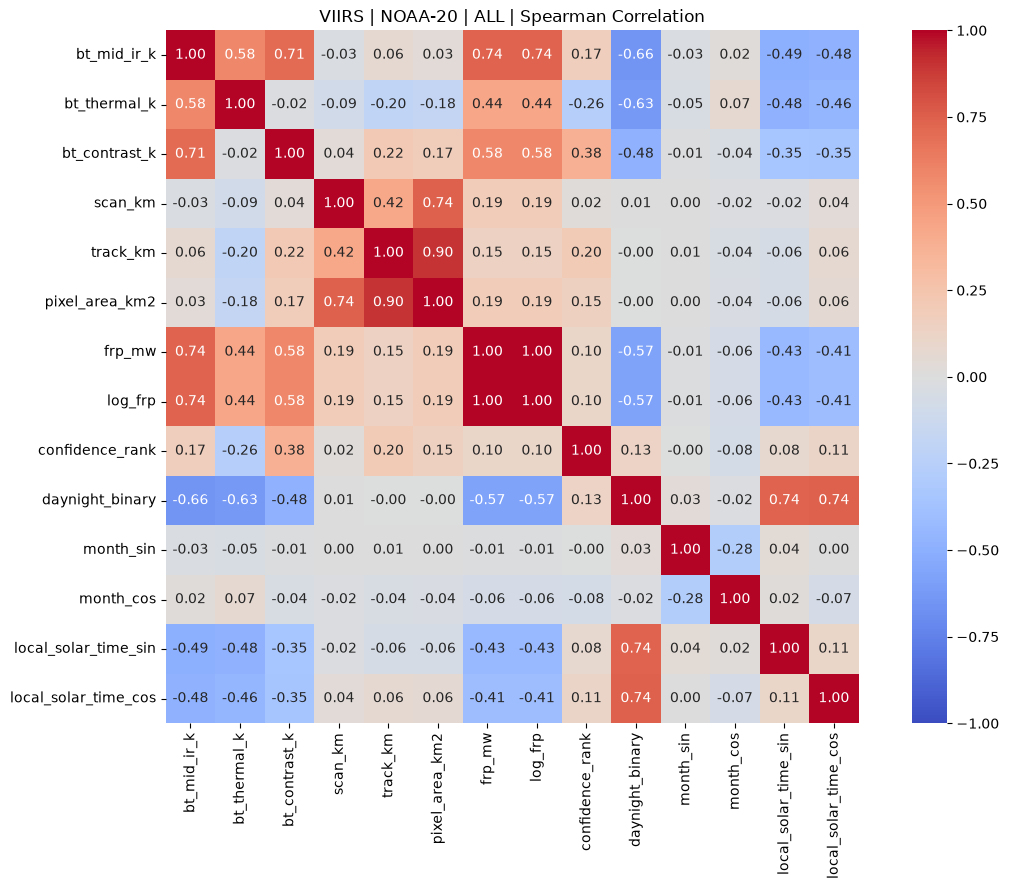

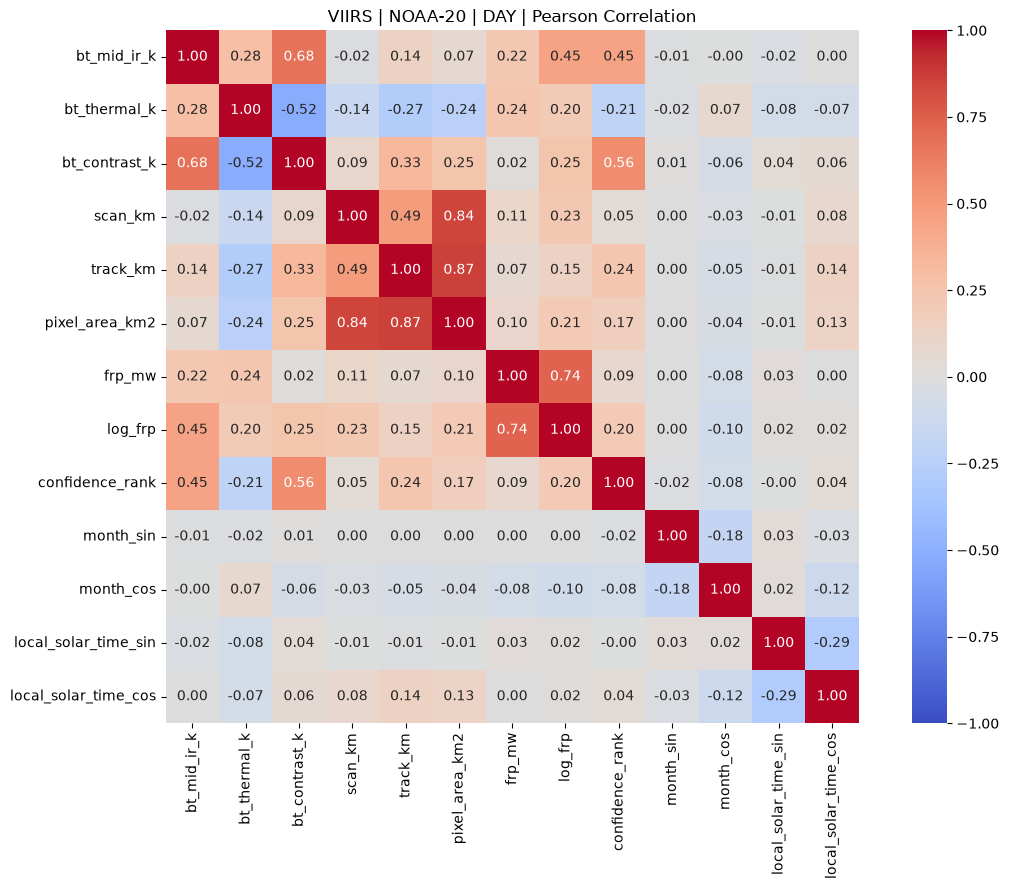

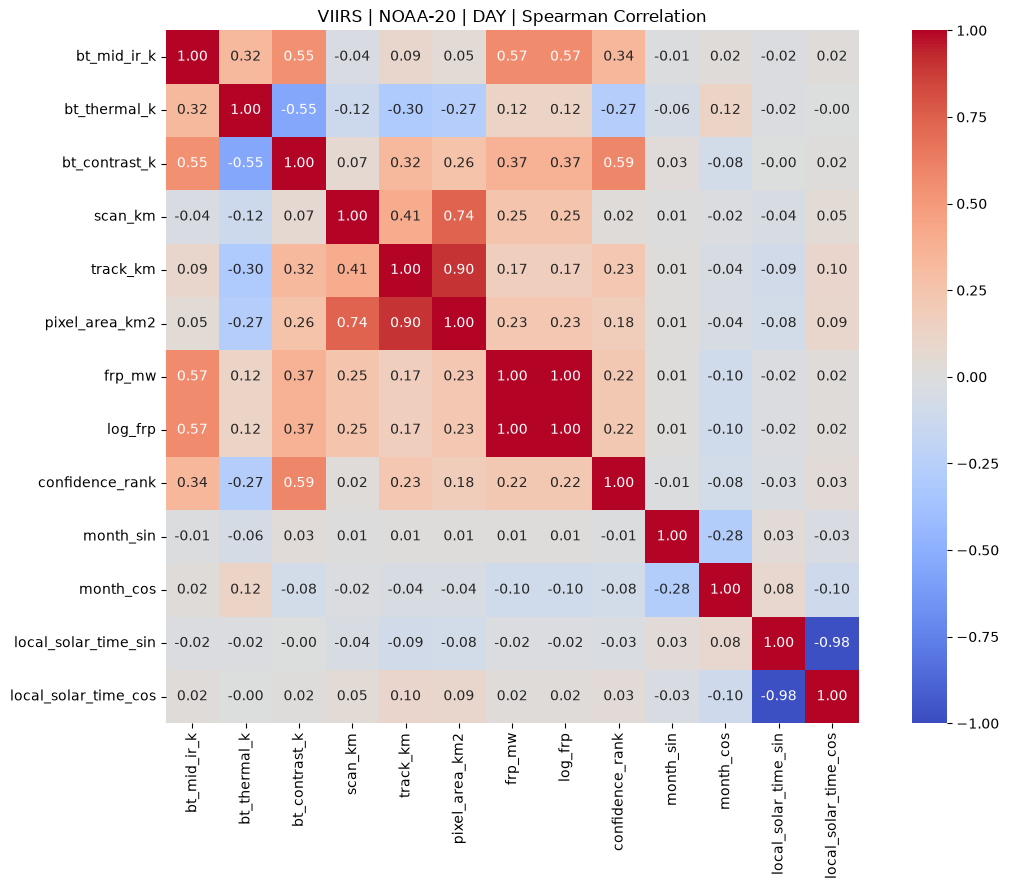

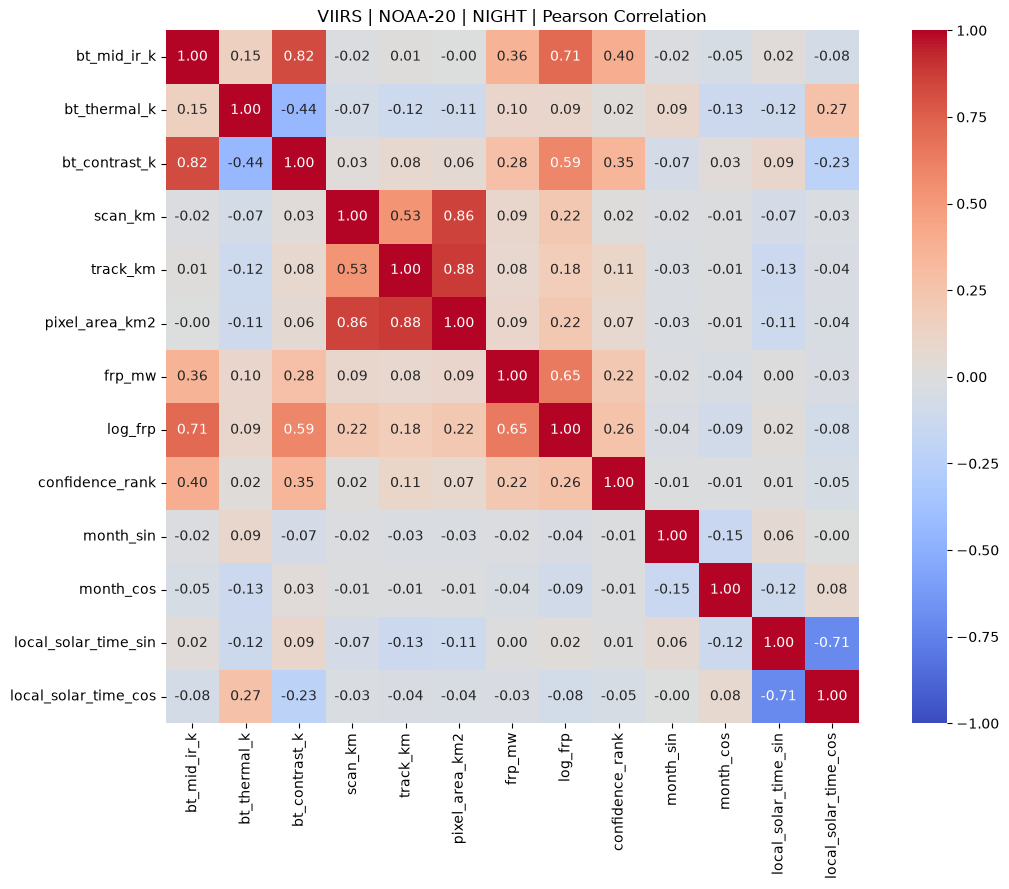

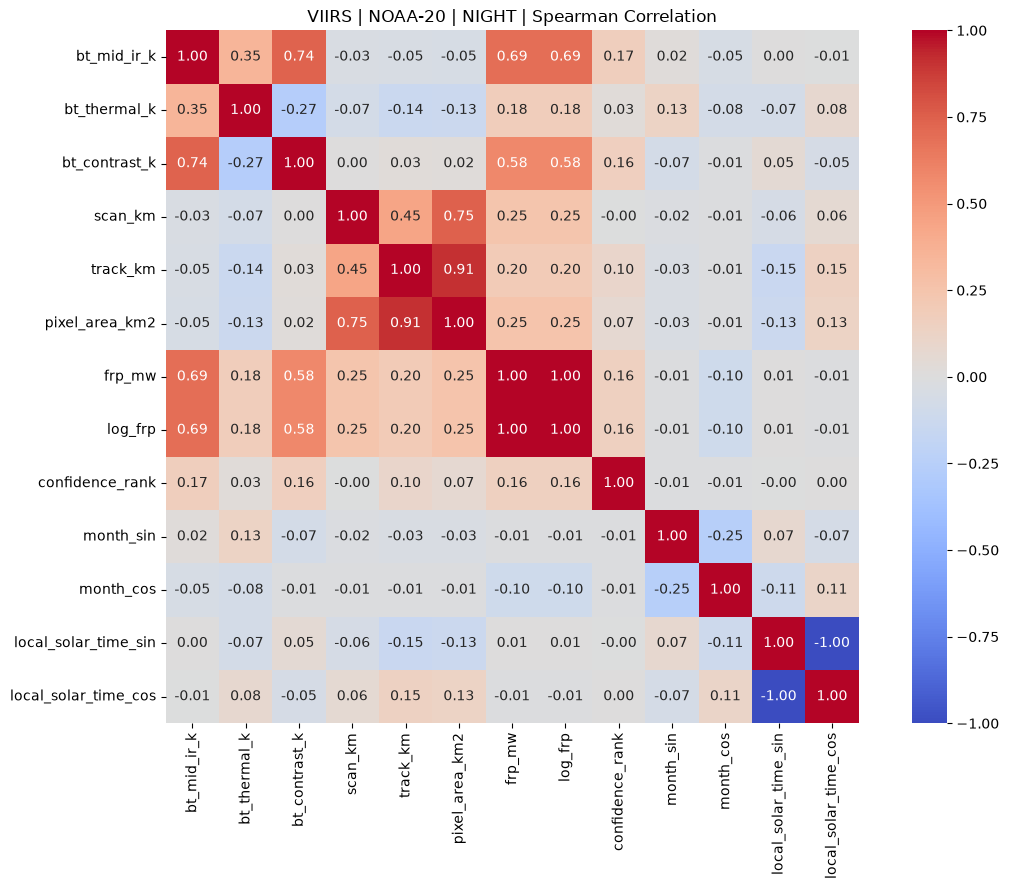

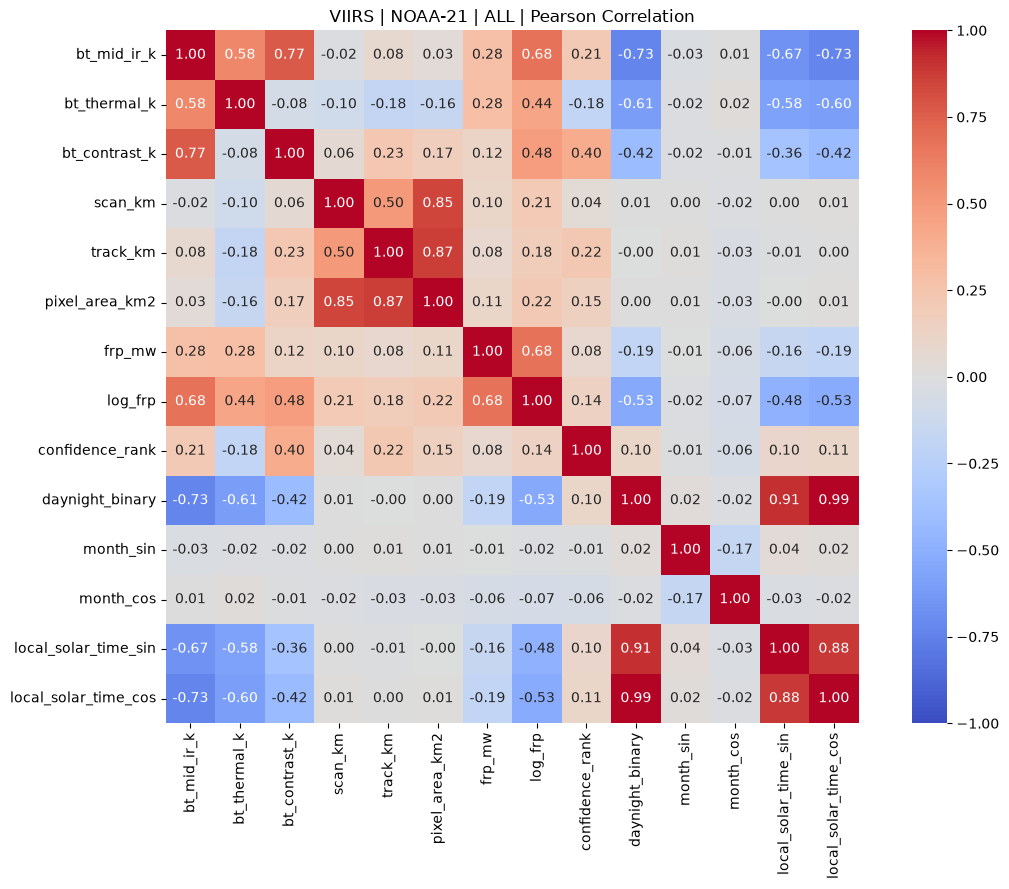

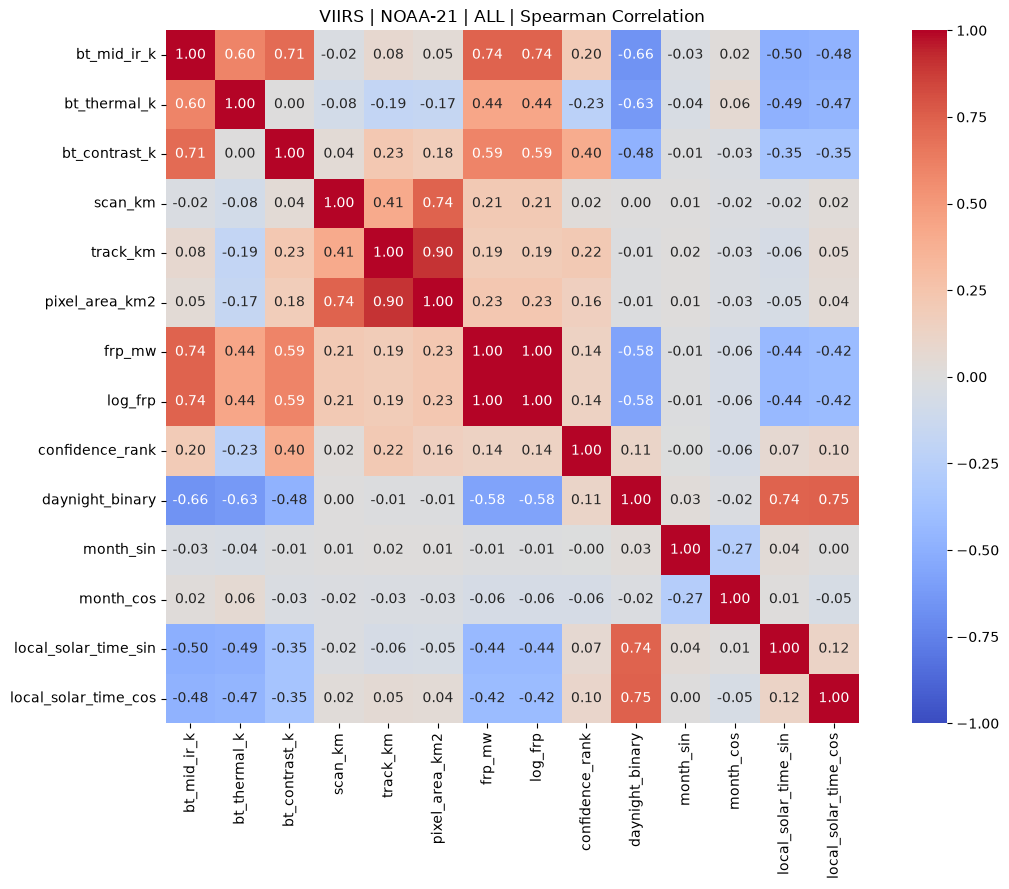

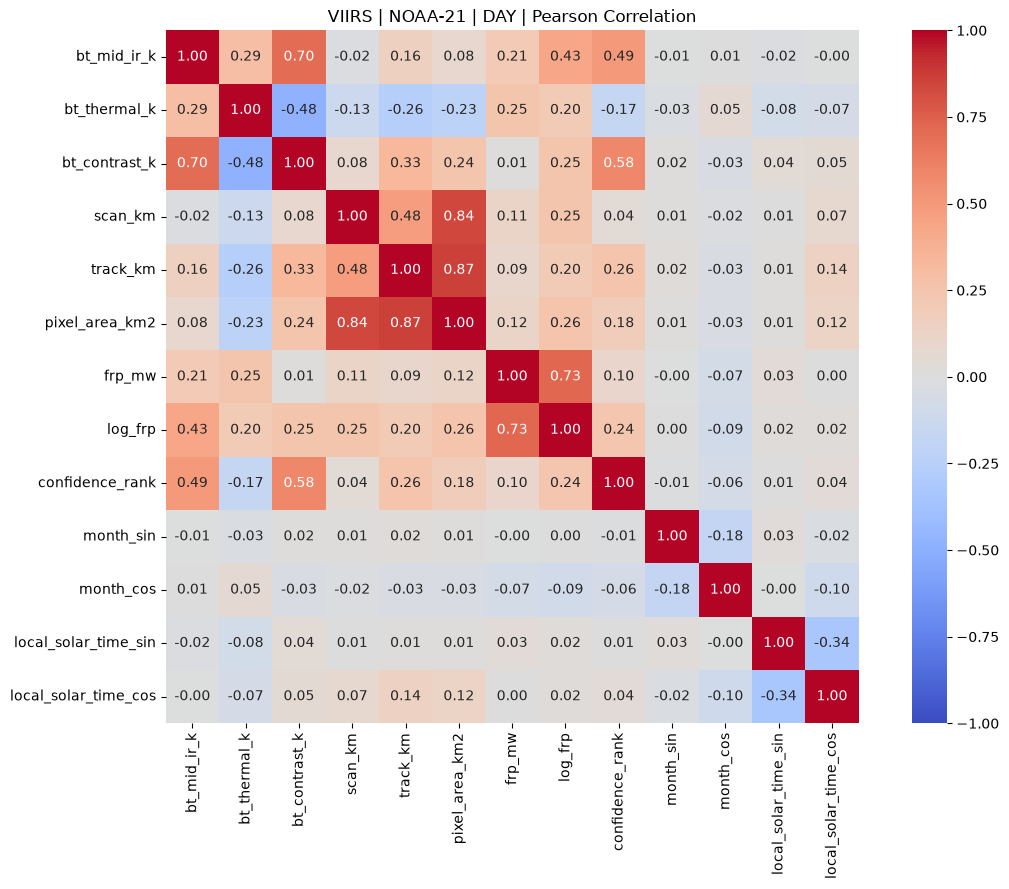

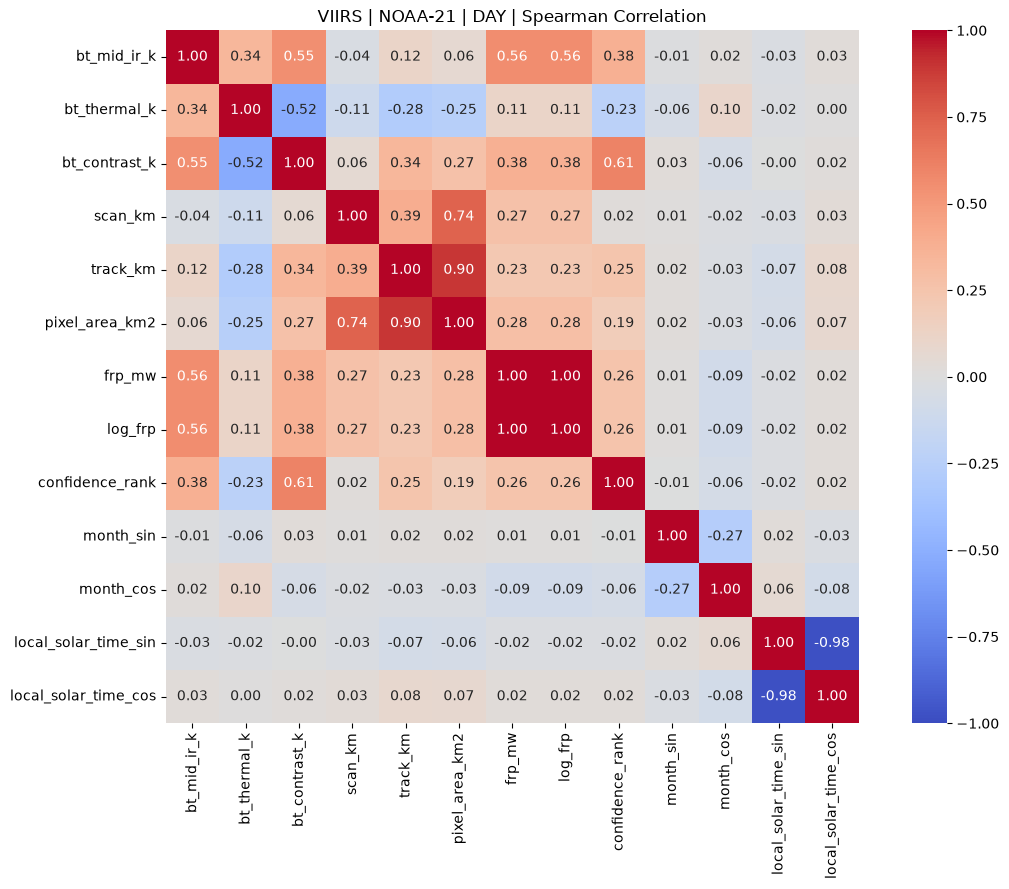

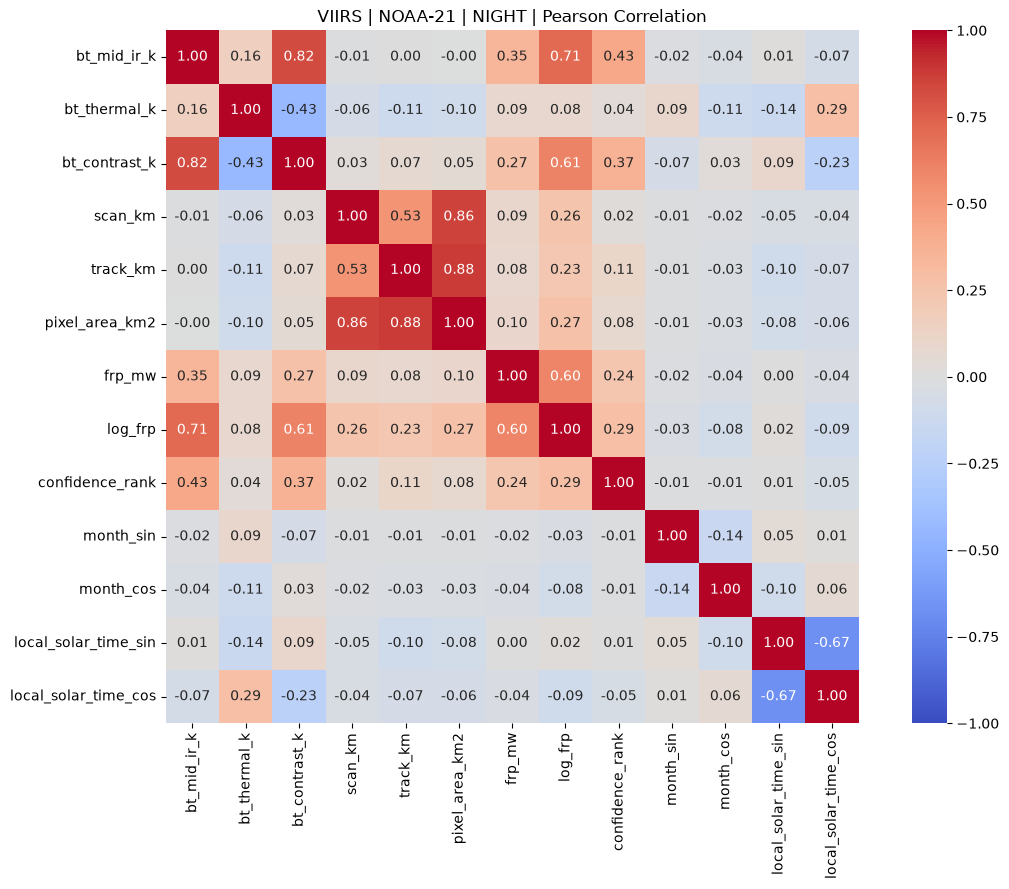

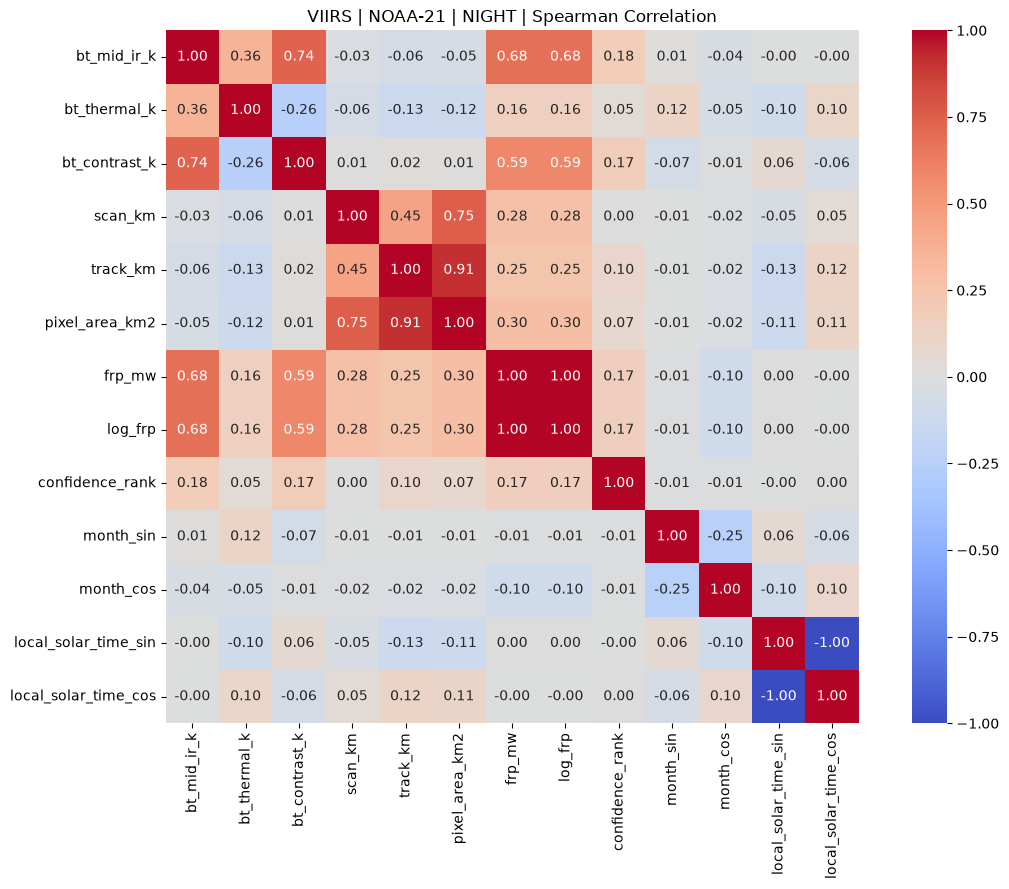

Successfully plotted 24 correlation matrices.


24

In [10]:
plot_all_correlation_results(correlation_results=correlation_results)

so confidence in VIIRS is mapped to three things (low = 7, nomial = 8, high = 9)